# MLP (Perceptron multicouche) : cas de tests du prof


## 1. Mise en place

In [1]:
import os, sys, subprocess
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../python")
import mlp_wrapper as mw
from mlp_wrapper import MLP

LIB = "../python/libmlp.so"
if not os.path.exists(LIB):
    subprocess.run(["g++", "-std=c++20", "-shared", "-fPIC", "-O2", "-o", LIB, "../src/MLP.cpp"], check=True)
mw.load_library(os.path.abspath(LIB))

In [2]:
RESULTATS = []


def entrainer(layers, task, X, Y, alpha, epochs, essais=1):
    meilleur, meilleur_score = None, None
    for graine in range(essais):
        modele = MLP(layers, task=task, seed=graine)
        modele.fit(X, Y, alpha=alpha, epochs=epochs)
        score = modele.score(X, Y)
        reussi = score >= 0.95 if task == "classification" else score < 0.05
        if reussi:
            return modele
        if meilleur is None or (score > meilleur_score if task == "classification" else score < meilleur_score):
            meilleur, meilleur_score = modele, score
    return meilleur


def noter(cas, attendu, modele, X, Y):
    score = modele.score(X, Y)
    if modele.task == "classification":
        verdict = "OK" if score >= 0.95 else "KO"
        print(f"{cas} : {score:.1%} de bonnes réponses -> {verdict} (attendu : {attendu})")
    else:
        verdict = "OK" if score < 0.05 else "KO"
        print(f"{cas} : erreur absolue moyenne = {score:.4f} -> {verdict} (attendu : {attendu})")
    RESULTATS.append((cas, str(modele.layers), attendu, verdict))


def afficher_classification(modele, X, Y):
    Y = np.array(Y).reshape(len(X), -1)
    xs = np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 150)
    ys = np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 150)
    xx, yy = np.meshgrid(xs, ys)
    grille = np.c_[xx.ravel(), yy.ravel()]
    plt.figure(figsize=(4.5, 3.8))
    if Y.shape[1] == 1:
        zone = modele.predict_class(grille).reshape(xx.shape)
        plt.contourf(xx, yy, zone, levels=[-2, 0, 2], colors=["#f4a6a6", "#a6c8f4"])
        plt.scatter(X[Y[:, 0] == 1, 0], X[Y[:, 0] == 1, 1], color="blue", edgecolor="k")
        plt.scatter(X[Y[:, 0] == -1, 0], X[Y[:, 0] == -1, 1], color="red", edgecolor="k")
    else:
        zone = np.argmax(modele.predict(grille), axis=1).reshape(xx.shape)
        plt.contourf(xx, yy, zone, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#a6c8f4", "#f4a6a6", "#a6e0a6"])
        for c, couleur in enumerate(["blue", "red", "green"]):
            plt.scatter(X[Y[:, c] == 1, 0], X[Y[:, c] == 1, 1], color=couleur, edgecolor="k", s=12)
    plt.show()


def afficher_regression(modele, X, Y):
    if X.shape[1] == 1:
        xs = np.linspace(X.min() - 0.5, X.max() + 0.5, 200).reshape(-1, 1)
        plt.figure(figsize=(4.5, 3.8))
        plt.plot(xs, modele.predict(xs))
        plt.scatter(X, Y, color="red", zorder=3)
    else:
        gx = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 30)
        gy = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 30)
        xx, yy = np.meshgrid(gx, gy)
        Z = modele.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax = plt.figure(figsize=(4.5, 3.8)).add_subplot(projection="3d")
        ax.plot_surface(xx, yy, Z, alpha=0.5, cmap="viridis")
        ax.scatter(X[:, 0], X[:, 1], Y, color="red", s=50)
    plt.show()

## 2. Classification
Les données sont celles du notebook du prof. Pour chaque cas, le titre rappelle ce que le prof attend pour le MLP.
Les points bleus et rouges sont les classes, le fond coloré est la réponse du réseau.

### Linear Simple
Prof : `MLP (2, 1) : OK`

Linear Simple : 100.0% de bonnes réponses -> OK (attendu : OK)


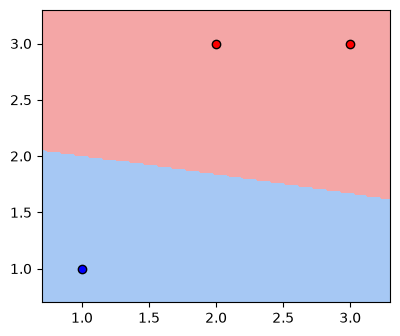

In [3]:
X = np.array([[1, 1], [2, 3], [3, 3]])
Y = np.array([1, -1, -1])

modele = entrainer([2, 1], "classification", X, Y, alpha=0.1, epochs=1000)
noter("Linear Simple", "OK", modele, X, Y)
afficher_classification(modele, X, Y)

### Linear Multiple
Prof : `MLP (2, 1) : OK`

Linear Multiple : 100.0% de bonnes réponses -> OK (attendu : OK)


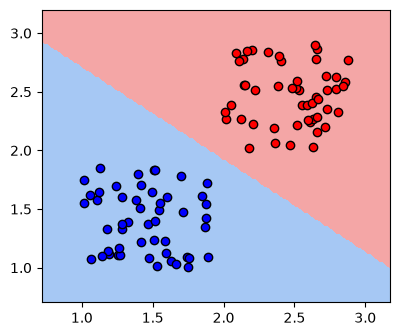

In [4]:
np.random.seed(0)
X = np.concatenate([np.random.random((50, 2)) * 0.9 + np.array([1, 1]), np.random.random((50, 2)) * 0.9 + np.array([2, 2])])
Y = np.concatenate([np.ones((50, 1)), np.ones((50, 1)) * -1.0])

modele = entrainer([2, 1], "classification", X, Y, alpha=0.1, epochs=500)
noter("Linear Multiple", "OK", modele, X, Y)
afficher_classification(modele, X, Y)

### XOR
Prof : `MLP (2, 2, 1) : OK` (une droite ne suffit pas, il faut une couche cachée)

XOR : 100.0% de bonnes réponses -> OK (attendu : OK)


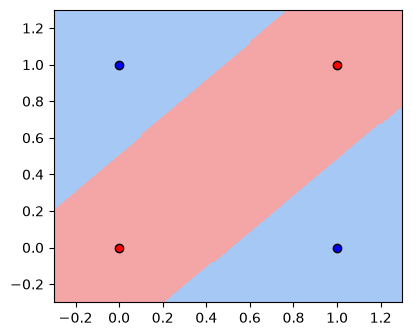

In [5]:
X = np.array([[1, 0], [0, 1], [0, 0], [1, 1]])
Y = np.array([1, 1, -1, -1])

modele = entrainer([2, 2, 1], "classification", X, Y, alpha=0.3, epochs=10000, essais=20)
noter("XOR", "OK", modele, X, Y)
afficher_classification(modele, X, Y)

### Cross
Prof : `MLP (2, 4, 1) : OK`

Cross : 99.2% de bonnes réponses -> OK (attendu : OK)


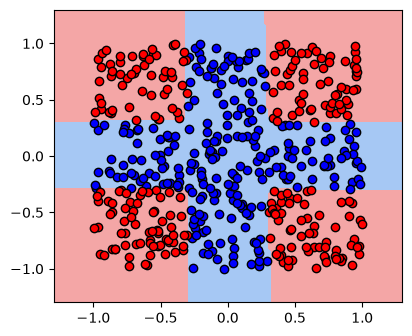

In [6]:
np.random.seed(0)
X = np.random.random((500, 2)) * 2.0 - 1.0
Y = np.array([1 if abs(p[0]) <= 0.3 or abs(p[1]) <= 0.3 else -1 for p in X])

modele = entrainer([2, 4, 1], "classification", X, Y, alpha=0.05, epochs=4000, essais=10)
noter("Cross", "OK", modele, X, Y)
afficher_classification(modele, X, Y)

### Multi Linear 3 classes
Prof : `MLP (2, 3) : OK` (3 sorties, la plus forte donne la classe)

Multi Linear 3 classes : 100.0% de bonnes réponses -> OK (attendu : OK)


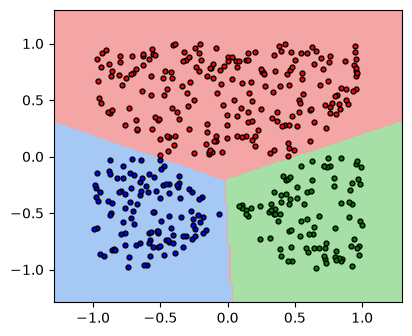

In [7]:
np.random.seed(0)
X = np.random.random((500, 2)) * 2.0 - 1.0
Y = np.array([[1, -1, -1] if -p[0] - p[1] - 0.5 > 0 and p[1] < 0 and p[0] - p[1] - 0.5 < 0 else
              [-1, 1, -1] if -p[0] - p[1] - 0.5 < 0 and p[1] > 0 and p[0] - p[1] - 0.5 < 0 else
              [-1, -1, 1] if -p[0] - p[1] - 0.5 < 0 and p[1] < 0 and p[0] - p[1] - 0.5 > 0 else
              [-1, -1, -1] for p in X])
garder = [not np.all(ligne == [-1, -1, -1]) for ligne in Y]
X, Y = X[garder], Y[garder]

modele = entrainer([2, 3], "classification", X, Y, alpha=0.05, epochs=2000, essais=5)
noter("Multi Linear 3 classes", "OK", modele, X, Y)
afficher_classification(modele, X, Y)

### Multi Cross
Prof : `MLP (2, ?, ?, 3) : OK` (nous choisissons 32 neurones par couche cachée)

Multi Cross : 95.9% de bonnes réponses -> OK (attendu : OK)


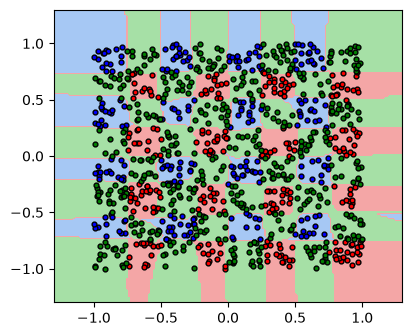

In [8]:
np.random.seed(0)
X = np.random.random((1000, 2)) * 2.0 - 1.0
Y = np.array([[1, -1, -1] if abs(p[0] % 0.5) <= 0.25 and abs(p[1] % 0.5) > 0.25 else
              [-1, 1, -1] if abs(p[0] % 0.5) > 0.25 and abs(p[1] % 0.5) <= 0.25 else
              [-1, -1, 1] for p in X])

modele = entrainer([2, 32, 32, 3], "classification", X, Y, alpha=0.02, epochs=3000, essais=5)
noter("Multi Cross", "OK", modele, X, Y)
afficher_classification(modele, X, Y)

## 3. Régression
La sortie du réseau est linéaire (pas de Tanh sur la dernière couche). Les points rouges sont les exemples, la courbe ou la surface est la réponse du réseau.

### Linear Simple 2D
Prof : `MLP (1, 1) : OK`

Linear Simple 2D : erreur absolue moyenne = 0.0000 -> OK (attendu : OK)


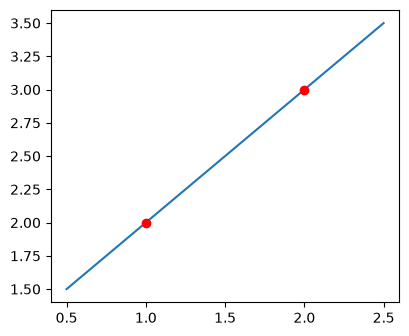

In [9]:
X = np.array([[1], [2]])
Y = np.array([2, 3])

modele = entrainer([1, 1], "regression", X, Y, alpha=0.05, epochs=2000)
noter("Linear Simple 2D", "OK", modele, X, Y)
afficher_regression(modele, X, Y)

### Non Linear Simple 2D
Prof : `MLP (1, ?, 1) : OK` (nous choisissons 4 neurones cachés)

Non Linear Simple 2D : erreur absolue moyenne = 0.0000 -> OK (attendu : OK)


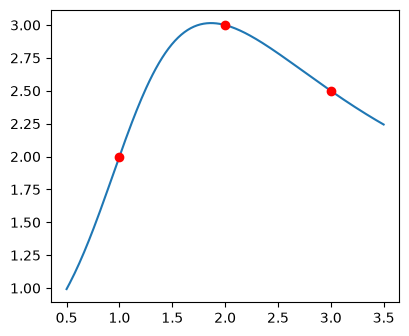

In [10]:
X = np.array([[1], [2], [3]])
Y = np.array([2, 3, 2.5])

modele = entrainer([1, 4, 1], "regression", X, Y, alpha=0.05, epochs=10000, essais=10)
noter("Non Linear Simple 2D", "OK", modele, X, Y)
afficher_regression(modele, X, Y)

### Linear Simple 3D
Prof : `MLP (2, 1) : OK`

Linear Simple 3D : erreur absolue moyenne = 0.0026 -> OK (attendu : OK)


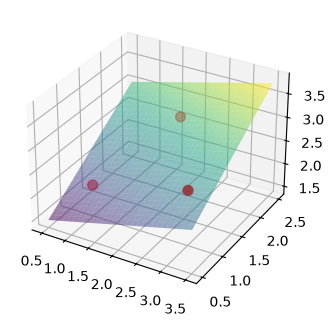

In [11]:
X = np.array([[1, 1], [2, 2], [3, 1]])
Y = np.array([2, 3, 2.5])

modele = entrainer([2, 1], "regression", X, Y, alpha=0.01, epochs=3000)
noter("Linear Simple 3D", "OK", modele, X, Y)
afficher_regression(modele, X, Y)

### Linear Tricky 3D
Prof : `MLP (2, 1) : OK` (les 3 points sont alignés)

Linear Tricky 3D : erreur absolue moyenne = 0.0000 -> OK (attendu : OK)


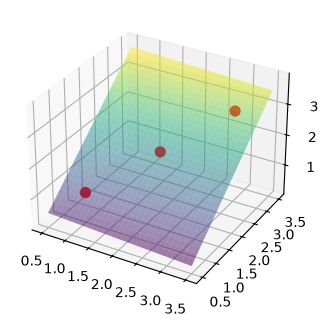

In [12]:
X = np.array([[1, 1], [2, 2], [3, 3]])
Y = np.array([1, 2, 3])

modele = entrainer([2, 1], "regression", X, Y, alpha=0.01, epochs=3000)
noter("Linear Tricky 3D", "OK", modele, X, Y)
afficher_regression(modele, X, Y)

### Non Linear Simple 3D
Prof : `MLP (2, 2, 1) : OK`

Non Linear Simple 3D : erreur absolue moyenne = 0.0000 -> OK (attendu : OK)


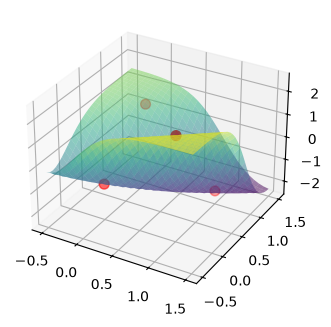

In [13]:
X = np.array([[1, 0], [0, 1], [1, 1], [0, 0]])
Y = np.array([2, 1, -2, -1])

modele = entrainer([2, 2, 1], "regression", X, Y, alpha=0.05, epochs=10000, essais=20)
noter("Non Linear Simple 3D", "OK", modele, X, Y)
afficher_regression(modele, X, Y)

### Récapitulatif des 11 cas

In [14]:
print(f"{'Cas':24s} {'MLP':16s} {'attendu':>8s} {'obtenu':>7s}")
for cas, archi, attendu, obtenu in RESULTATS:
    print(f"{cas:24s} {archi:16s} {attendu:>8s} {obtenu:>7s}")
print(f"\n{sum(r[2] == r[3] for r in RESULTATS)} cas sur {len(RESULTATS)} conformes à ce que le prof attend.")

Cas                      MLP               attendu  obtenu
Linear Simple            [2, 1]                 OK      OK
Linear Multiple          [2, 1]                 OK      OK
XOR                      [2, 2, 1]              OK      OK
Cross                    [2, 4, 1]              OK      OK
Multi Linear 3 classes   [2, 3]                 OK      OK
Multi Cross              [2, 32, 32, 3]         OK      OK
Linear Simple 2D         [1, 1]                 OK      OK
Non Linear Simple 2D     [1, 4, 1]              OK      OK
Linear Simple 3D         [2, 1]                 OK      OK
Linear Tricky 3D         [2, 1]                 OK      OK
Non Linear Simple 3D     [2, 2, 1]              OK      OK

11 cas sur 11 conformes à ce que le prof attend.
